## Injecting artificial lines

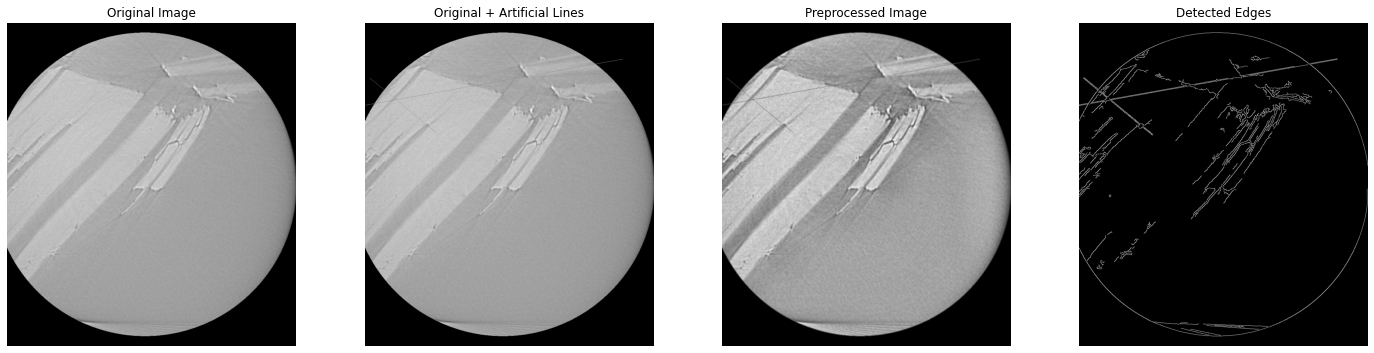

In [13]:
import os
import numpy as np
import tifffile
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from skimage.exposure import rescale_intensity, equalize_adapthist
import cv2

# Step 1: Preprocessing Function
def preprocess_image(image, sigma=1, clip_limit=0.01):
    """Preprocess a single image: denoise and enhance contrast."""
    # Denoising
    denoised_image = gaussian_filter(image, sigma=sigma)

    # Normalize to [0, 1]
    normalized_image = rescale_intensity(denoised_image, in_range='image', out_range=(0, 1))

    # Contrast enhancement
    enhanced_image = equalize_adapthist(normalized_image, clip_limit=clip_limit)
    return enhanced_image

# Step 2: Artificial Line Injection Function
def inject_artificial_lines(image, num_lines=5, thickness=1, intensity_scale=0.1):
    """
    Inject artificial lines into an image to simulate subtle tracks.
    The lines will have a slight intensity increase/decrease relative to the background.
    
    Parameters:
    - image: Input 2D image array
    - num_lines: Number of lines to inject
    - thickness: Thickness of the injected lines
    - intensity_scale: Scaling factor to adjust line intensity relative to the image
    
    Returns:
    - line_image: Image with artificial lines
    """
    height, width = image.shape
    line_image = np.copy(image)

    for _ in range(num_lines):
        # Random start and end points for lines
        x1, y1 = np.random.randint(0, width), np.random.randint(0, height)
        x2, y2 = np.random.randint(0, width), np.random.randint(0, height)

        # Adjust line intensity to be subtle
        mean_intensity = np.mean(image)
        line_intensity = mean_intensity + intensity_scale * mean_intensity

        # Draw line with subtle intensity changes
        cv2.line(line_image, (x1, y1), (x2, y2), color=(line_intensity), thickness=thickness)

    return line_image

# Step 3: Edge Detection Function
def detect_edges(image):
    """Detect edges in the image using the Canny Edge Detector."""
    # Convert to uint8 for edge detection
    uint8_image = (image * 255).astype(np.uint8)
    edges = cv2.Canny(uint8_image, threshold1=50, threshold2=150)
    return edges

# Step 4: Visualization Function
def display_pipeline(original, original_with_lines, preprocessed, edges):
    """Display the pipeline steps for a single image."""
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))

    axes[0].imshow(original, cmap='gray')
    axes[0].set_title("Original Image")
    axes[0].axis('off')

    axes[1].imshow(original_with_lines, cmap='gray')
    axes[1].set_title("Original + Artificial Lines")
    axes[1].axis('off')

    axes[2].imshow(preprocessed, cmap='gray')
    axes[2].set_title("Preprocessed Image")
    axes[2].axis('off')

    axes[3].imshow(edges, cmap='gray')
    axes[3].set_title("Detected Edges")
    axes[3].axis('off')

    plt.tight_layout()
    plt.show()

# Paths
input_folder = "sample_1_cs_4_2"

# Step 5: Process and Visualize for One Image
# Load a single image
image_path = os.path.join(input_folder, "0132.tiff")  # Example image path
original_image = tifffile.imread(image_path)

# Inject artificial lines with subtle intensity changes
original_with_lines = inject_artificial_lines(original_image, num_lines=2, thickness=1, intensity_scale=0.1)

# Preprocess the original image with artificial lines
preprocessed_image = preprocess_image(original_with_lines)

# Detect edges
edges_detected = detect_edges(preprocessed_image)

# Display all steps
display_pipeline(original_image, original_with_lines, preprocessed_image, edges_detected)


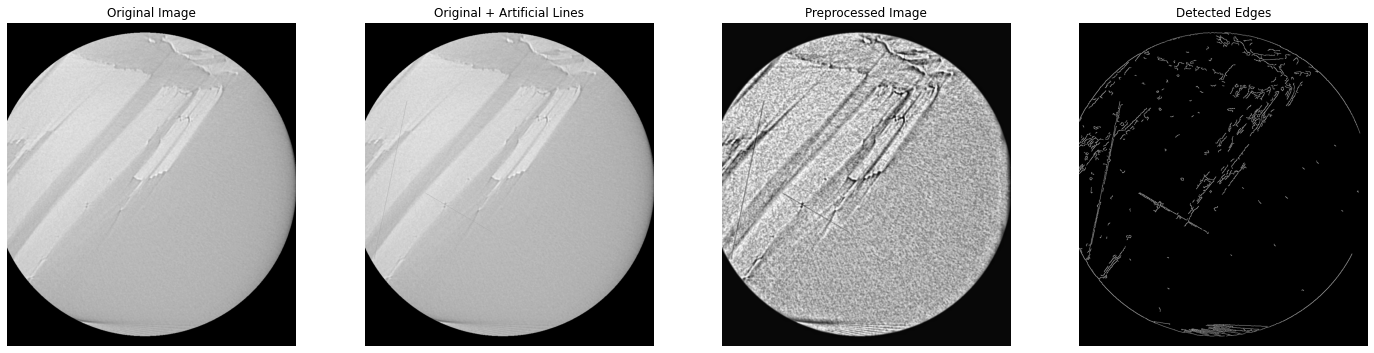

In [8]:
import os
import numpy as np
import tifffile
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from skimage.exposure import rescale_intensity, equalize_adapthist
import cv2

# Step 1: Preprocessing Function
def preprocess_image(image, sigma=1, clip_limit=10.0, tile_grid_size=(50, 50)):
    """Preprocess a single image: denoise, normalize, and enhance contrast."""
    # Denoising
    denoised_image = gaussian_filter(image, sigma=sigma)

    # Normalize to [0, 255]
    normalized_image = rescale_intensity(denoised_image, in_range='image', out_range=(0, 255)).astype(np.uint8)

    # Enhance contrast using CLAHE
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid_size)
    enhanced_image = clahe.apply(normalized_image)

    return enhanced_image

# Step 2: Artificial Line Injection Function
def inject_artificial_lines(image, num_lines=5, thickness=1, intensity_scale=0.1):
    """
    Inject artificial lines into an image to simulate subtle tracks.
    The lines will have a slight intensity increase/decrease relative to the background.
    
    Parameters:
    - image: Input 2D image array
    - num_lines: Number of lines to inject
    - thickness: Thickness of the injected lines
    - intensity_scale: Scaling factor to adjust line intensity relative to the image
    
    Returns:
    - line_image: Image with artificial lines
    """
    height, width = image.shape
    line_image = np.copy(image)

    for _ in range(num_lines):
        # Random start and end points for lines
        x1, y1 = np.random.randint(0, width), np.random.randint(0, height)
        x2, y2 = np.random.randint(0, width), np.random.randint(0, height)

        # Adjust line intensity to be subtle
        mean_intensity = np.mean(image)
        line_intensity = mean_intensity + intensity_scale * mean_intensity

        # Draw line with subtle intensity changes
        cv2.line(line_image, (x1, y1), (x2, y2), color=(line_intensity), thickness=thickness)

    return line_image

# Step 3: Edge Detection Function
def detect_edges(image):
    """Detect edges in the image using the Canny Edge Detector."""
    # Convert to uint8 for edge detection
    uint8_image = image.astype(np.uint8)
    edges = cv2.Canny(uint8_image, threshold1=200, threshold2=400)
    return edges

# Step 4: Visualization Function
def display_pipeline(original, original_with_lines, preprocessed, edges):
    """Display the pipeline steps for a single image."""
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))

    axes[0].imshow(original, cmap='gray')
    axes[0].set_title("Original Image")
    axes[0].axis('off')

    axes[1].imshow(original_with_lines, cmap='gray')
    axes[1].set_title("Original + Artificial Lines")
    axes[1].axis('off')

    axes[2].imshow(preprocessed, cmap='gray')
    axes[2].set_title("Preprocessed Image")
    axes[2].axis('off')

    axes[3].imshow(edges, cmap='gray')
    axes[3].set_title("Detected Edges")
    axes[3].axis('off')

    plt.tight_layout()
    plt.show()

# Paths
input_folder = "sample_1_cs_4_2"

# Step 5: Process and Visualize for One Image
# Load a single image
image_path = os.path.join(input_folder, "0015.tiff")  # Example image path
original_image = tifffile.imread(image_path)

# Inject artificial lines with subtle intensity changes
original_with_lines = inject_artificial_lines(original_image, num_lines=2, thickness=1, intensity_scale=0.1)

# Preprocess the original image with artificial lines
preprocessed_image = preprocess_image(original_with_lines)

# Detect edges
edges_detected = detect_edges(preprocessed_image)

# Display all steps
display_pipeline(original_image, original_with_lines, preprocessed_image, edges_detected)


## Preprocessing for ML

In [9]:
import random
import shutil
#Step 6: Prepare Dataset with Random File Selection
def prepare_dataset(input_folder, output_folder, num_files=100, inject_probability=0.5, num_lines=5, thickness=1, intensity_scale=0.2):
    """
    Prepare a dataset with random files from the input directory.
    Inject artificial lines into a subset of images and save all to a new directory.
    Preprocess the images before saving.
    
    Parameters:
    - input_folder: Directory containing original images
    - output_folder: Directory to save processed images
    - num_files: Number of random files to select
    - inject_probability: Probability of injecting lines into an image
    - num_lines: Number of lines to inject
    - thickness: Thickness of the lines
    - intensity_scale: Intensity scaling for artificial lines
    
    Returns:
    - injected_files: List of files where lines were injected
    """
    os.makedirs(output_folder, exist_ok=True)
    file_list = [f for f in os.listdir(input_folder) if f.endswith('.tiff')]
    
    if num_files > len(file_list):
        raise ValueError(f"Requested {num_files} files, but only {len(file_list)} available.")

    selected_files = random.sample(file_list, num_files)
    injected_files = []

    for file_name in selected_files:
        file_path = os.path.join(input_folder, file_name)
        original_image = tifffile.imread(file_path)

        # Decide whether to inject artificial lines
        if random.random() < inject_probability:
            processed_image = inject_artificial_lines(original_image, num_lines=num_lines, thickness=thickness, intensity_scale=intensity_scale)
            new_file_name = f"{os.path.splitext(file_name)[0]}_injected.tiff"
            injected_files.append(new_file_name)
        else:
            processed_image = original_image
            new_file_name = file_name

        # Preprocess the image
        preprocessed_image = preprocess_image(processed_image)

        # Save the preprocessed image
        output_path = os.path.join(output_folder, new_file_name)
        tifffile.imwrite(output_path, preprocessed_image)
        print(f"Saved: {output_path}")

    return injected_files

# Example Usage
input_folder = "sample_1_cs_4_2"  
output_folder = "processed_dataset"  # Output directory for new dataset

# Prepare the dataset
injected_files = prepare_dataset(input_folder=input_folder, output_folder=output_folder, num_files=200, inject_probability=0.2, num_lines=2, thickness=1, intensity_scale=0.2)

# Print injected files for comparison
print("Injected Files:")
print("\n".join(injected_files))


Saved: processed_dataset/0581.tiff
Saved: processed_dataset/0307.tiff
Saved: processed_dataset/0263.tiff
Saved: processed_dataset/0226.tiff
Saved: processed_dataset/0472_injected.tiff
Saved: processed_dataset/0200.tiff
Saved: processed_dataset/0326.tiff
Saved: processed_dataset/0046.tiff
Saved: processed_dataset/0434.tiff
Saved: processed_dataset/0445.tiff
Saved: processed_dataset/0792.tiff
Saved: processed_dataset/0176.tiff
Saved: processed_dataset/0253_injected.tiff
Saved: processed_dataset/0198.tiff
Saved: processed_dataset/0640.tiff
Saved: processed_dataset/0462.tiff
Saved: processed_dataset/0371.tiff
Saved: processed_dataset/0078.tiff
Saved: processed_dataset/0296.tiff
Saved: processed_dataset/0011.tiff
Saved: processed_dataset/0689.tiff
Saved: processed_dataset/0537_injected.tiff
Saved: processed_dataset/0533.tiff
Saved: processed_dataset/0375.tiff
Saved: processed_dataset/0247.tiff
Saved: processed_dataset/0027.tiff
Saved: processed_dataset/0031_injected.tiff
Saved: processed_da

## ML Application

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
import joblib

# Step 7: Feature Extraction Function
def extract_features(image):
    """
    Extract features from an image for ML classification.
    Features include:
    - Edge density: Proportion of edge pixels to total pixels
    - Mean pixel intensity
    - Standard deviation of pixel intensity
    """
    preprocessed_image = preprocess_image(image)
    edges = detect_edges(preprocessed_image)
    edge_density = np.sum(edges) / edges.size
    mean_intensity = np.mean(preprocessed_image)
    std_intensity = np.std(preprocessed_image)
    return [edge_density, mean_intensity, std_intensity]

# Step 8: Analyze Dataset Using ML
def analyze_dataset_ml(dataset_folder, injected_file_list):
    """
    Analyze the dataset to classify images using ML based on edge density and intensity features.
    
    Parameters:
    - dataset_folder: Directory containing the processed images
    - injected_file_list: List of filenames where lines were injected
    
    Returns:
    - None (prints classification report and saves the model)
    """
    # Get list of image files
    file_list = [f for f in os.listdir(dataset_folder) if f.endswith('.tiff')]
    features = []
    labels = []

    # Extract features and create labels
    for file_name in file_list:
        file_path = os.path.join(dataset_folder, file_name)
        image = tifffile.imread(file_path)
        feature_vector = extract_features(image)
        features.append(feature_vector)
        labels.append(1 if file_name in injected_file_list else 0)  # 1 for "Injected", 0 for "Original"

    # Split into training and testing datasets
    X_train, X_test, y_train, y_test = train_test_split(features, labels, test_size=0.2, random_state=42)

    # Train a Random Forest Classifier
    model = RandomForestClassifier(n_estimators=100, random_state=42)
    model.fit(X_train, y_train)

    # Evaluate the model
    y_pred = model.predict(X_test)
    print("Classification Report:")
    print(classification_report(y_test, y_pred, target_names=["Original", "Injected"]))

    # Save the trained model
    model_path = os.path.join(dataset_folder, "line_detection_model.pkl")
    joblib.dump(model, model_path)
    print(f"Model saved to {model_path}")

# Example Usage
output_folder = "processed_dataset"  # Output folder from the dataset preparation step

# Prepare the injected file list (files with "_injected.tiff" suffix were injected)
injected_file_list = [f for f in os.listdir(output_folder) if "_injected" in f]

# Analyze the dataset with ML
analyze_dataset_ml(dataset_folder=output_folder, injected_file_list=injected_file_list)


Classification Report:
              precision    recall  f1-score   support

    Original       0.86      0.97      0.91        33
    Injected       0.67      0.29      0.40         7

    accuracy                           0.85        40
   macro avg       0.77      0.63      0.66        40
weighted avg       0.83      0.85      0.82        40

Model saved to processed_dataset/line_detection_model.pkl


Classification Report:
              precision    recall  f1-score   support

    Original       0.86      0.97      0.91        33
    Injected       0.67      0.29      0.40         7

    accuracy                           0.85        40
   macro avg       0.77      0.63      0.66        40
weighted avg       0.83      0.85      0.82        40

Model saved to processed_dataset/line_detection_model.pkl


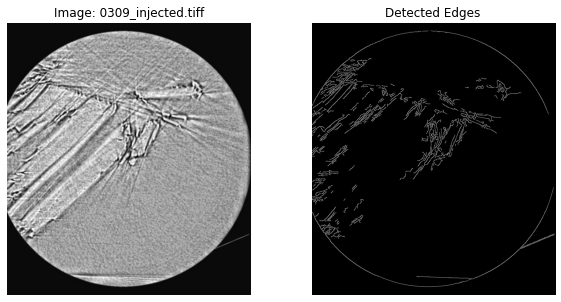

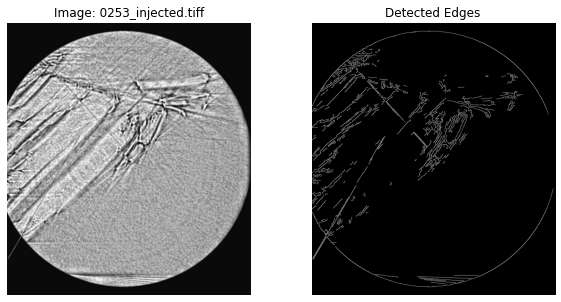

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
import joblib

# Step 8: Analyze Dataset Using ML and Visualize Identified Tracks
def analyze_dataset_ml(dataset_folder, injected_files):
    """
    Analyze the dataset to classify images using ML based on edge density and intensity features.
    Visualize one or two images identified as 'Injected' by the model.
    
    Parameters:
    - dataset_folder: Directory containing the processed images
    - injected_files: List of filenames where lines were injected
    
    Returns:
    - None (prints classification report and saves the model)
    """
    file_list = [f for f in os.listdir(dataset_folder) if f.endswith('.tiff')]
    features = []
    labels = []

    # Extract features and labels
    for file_name in file_list:
        file_path = os.path.join(dataset_folder, file_name)
        image = tifffile.imread(file_path)
        feature_vector = extract_features(image)
        features.append(feature_vector)
        labels.append(1 if file_name in injected_files else 0)  # 1 for "Injected", 0 for "Original"

    # Split into train and test sets
    X_train, X_test, y_train, y_test, train_files, test_files = train_test_split(
        features, labels, file_list, test_size=0.2, random_state=42
    )

    # Train a Random Forest Classifier
    model = RandomForestClassifier(n_estimators=100, random_state=42)
    model.fit(X_train, y_train)

    # Evaluate the model
    y_pred = model.predict(X_test)
    print("Classification Report:")
    print(classification_report(y_test, y_pred, target_names=["Original", "Injected"]))

    # Save the model for future use
    model_path = os.path.join(dataset_folder, "line_detection_model.pkl")
    joblib.dump(model, model_path)
    print(f"Model saved to {model_path}")

    # Visualize one or two identified tracks
    displayed = 0  # Counter for displayed images
    for i, (file_name, pred, true_label) in enumerate(zip(test_files, y_pred, y_test)):
        if pred == 1 and true_label == 1:  # Correctly identified 'Injected' files
            file_path = os.path.join(dataset_folder, file_name)
            image = tifffile.imread(file_path)
            edges = detect_edges(image)

            # Display the image and detected edges
            plt.figure(figsize=(10, 5))
            plt.subplot(1, 2, 1)
            plt.imshow(image, cmap='gray')
            plt.title(f"Image: {file_name}")
            plt.axis('off')

            plt.subplot(1, 2, 2)
            plt.imshow(edges, cmap='gray')
            plt.title("Detected Edges")
            plt.axis('off')

            plt.show()

            displayed += 1
            if displayed >= 2:  # Stop after displaying 2 images
                break

# Analyze the prepared dataset
analyze_dataset_ml(dataset_folder=output_folder, injected_files=injected_files)


Classification Report:
              precision    recall  f1-score   support

    Original       0.86      0.97      0.91        33
    Injected       0.67      0.29      0.40         7

    accuracy                           0.85        40
   macro avg       0.77      0.63      0.66        40
weighted avg       0.83      0.85      0.82        40

Model saved to processed_dataset/line_detection_model.pkl


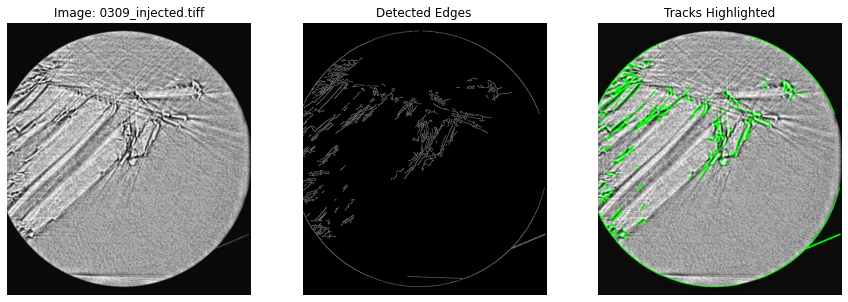

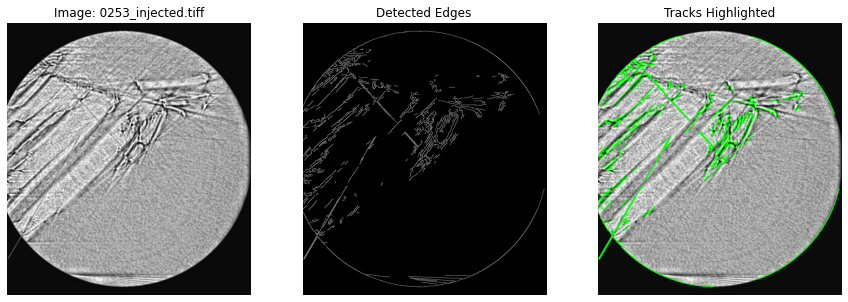

In [13]:
import cv2

# Modified visualization to mark identified tracks
def analyze_dataset_ml_with_highlight(dataset_folder, injected_files):
    """
    Analyze the dataset to classify images using ML based on edge density and intensity features.
    Visualize one or two images identified as 'Injected' by the model, marking the detected tracks.
    
    Parameters:
    - dataset_folder: Directory containing the processed images
    - injected_files: List of filenames where lines were injected
    
    Returns:
    - None (prints classification report and saves the model)
    """
    file_list = [f for f in os.listdir(dataset_folder) if f.endswith('.tiff')]
    features = []
    labels = []

    # Extract features and labels
    for file_name in file_list:
        file_path = os.path.join(dataset_folder, file_name)
        image = tifffile.imread(file_path)
        feature_vector = extract_features(image)
        features.append(feature_vector)
        labels.append(1 if file_name in injected_files else 0)  # 1 for "Injected", 0 for "Original"

    # Split into train and test sets
    X_train, X_test, y_train, y_test, train_files, test_files = train_test_split(
        features, labels, file_list, test_size=0.2, random_state=42
    )

    # Train a Random Forest Classifier
    model = RandomForestClassifier(n_estimators=100, random_state=42)
    model.fit(X_train, y_train)

    # Evaluate the model
    y_pred = model.predict(X_test)
    print("Classification Report:")
    print(classification_report(y_test, y_pred, target_names=["Original", "Injected"]))

    # Save the model for future use
    model_path = os.path.join(dataset_folder, "line_detection_model.pkl")
    joblib.dump(model, model_path)
    print(f"Model saved to {model_path}")

    # Visualize one or two identified tracks
    displayed = 0  # Counter for displayed images
    for i, (file_name, pred, true_label) in enumerate(zip(test_files, y_pred, y_test)):
        if pred == 1 and true_label == 1:  # Correctly identified 'Injected' files
            file_path = os.path.join(dataset_folder, file_name)
            image = tifffile.imread(file_path)
            edges = detect_edges(image)

            # Find contours from edges
            contours, _ = cv2.findContours(edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

            # Create a copy of the image to overlay tracks
            marked_image = cv2.cvtColor(image.astype(np.uint8), cv2.COLOR_GRAY2BGR)

            # Draw contours on the marked image
            for contour in contours:
                if cv2.contourArea(contour) > 10:  # Filter out small noise contours
                    cv2.drawContours(marked_image, [contour], -1, (0, 255, 0), 2)  # Green contours

            # Display the original, edges, and marked image
            plt.figure(figsize=(15, 5))

            plt.subplot(1, 3, 1)
            plt.imshow(image, cmap='gray')
            plt.title(f"Image: {file_name}")
            plt.axis('off')

            plt.subplot(1, 3, 2)
            plt.imshow(edges, cmap='gray')
            plt.title("Detected Edges")
            plt.axis('off')

            plt.subplot(1, 3, 3)
            plt.imshow(marked_image)
            plt.title("Tracks Highlighted")
            plt.axis('off')

            plt.show()

            displayed += 1
            if displayed >= 2:  # Stop after displaying 2 images
                break

# Analyze the dataset with highlighted tracks
analyze_dataset_ml_with_highlight(dataset_folder=output_folder, injected_files=injected_files)


Classification Report:
              precision    recall  f1-score   support

    Original       0.86      0.97      0.91        33
    Injected       0.67      0.29      0.40         7

    accuracy                           0.85        40
   macro avg       0.77      0.63      0.66        40
weighted avg       0.83      0.85      0.82        40

Model saved to processed_dataset/line_detection_model.pkl


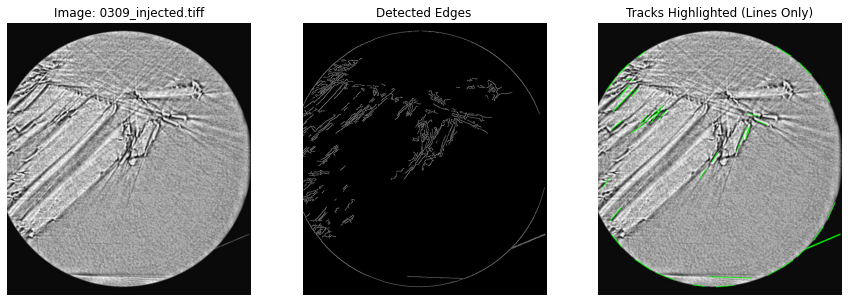

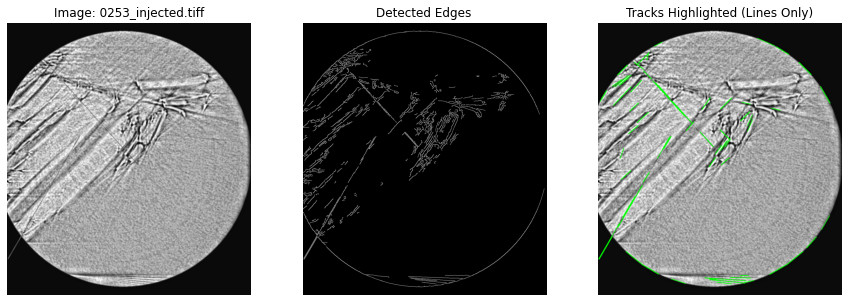

In [ ]:
import cv2

# Modified visualization to highlight identified lines only
def analyze_dataset_ml_with_lines(dataset_folder, injected_files):
    """
    Analyze the dataset to classify images using ML based on edge density and intensity features.
    Visualize one or two images identified as 'Injected' by the model, marking the detected tracks (lines only).
    
    Parameters:
    - dataset_folder: Directory containing the processed images
    - injected_files: List of filenames where lines were injected
    
    Returns:
    - None (prints classification report and saves the model)
    """
    file_list = [f for f in os.listdir(dataset_folder) if f.endswith('.tiff')]
    features = []
    labels = []

    # Extract features and labels
    for file_name in file_list:
        file_path = os.path.join(dataset_folder, file_name)
        image = tifffile.imread(file_path)
        feature_vector = extract_features(image)
        features.append(feature_vector)
        labels.append(1 if file_name in injected_files else 0)  # 1 for "Injected", 0 for "Original"

    # Split into train and test sets
    X_train, X_test, y_train, y_test, train_files, test_files = train_test_split(
        features, labels, file_list, test_size=0.2, random_state=42
    )

    # Train a Random Forest Classifier
    model = RandomForestClassifier(n_estimators=100, random_state=42)
    model.fit(X_train, y_train)

    # Evaluate the model
    y_pred = model.predict(X_test)
    print("Classification Report:")
    print(classification_report(y_test, y_pred, target_names=["Original", "Injected"]))

    # Save the model for future use
    model_path = os.path.join(dataset_folder, "line_detection_model.pkl")
    joblib.dump(model, model_path)
    print(f"Model saved to {model_path}")

    # Visualize one or two identified tracks
    displayed = 0  # Counter for displayed images
    for i, (file_name, pred, true_label) in enumerate(zip(test_files, y_pred, y_test)):
        if pred == 1 and true_label == 1:  # Correctly identified 'Injected' files
            file_path = os.path.join(dataset_folder, file_name)
            image = tifffile.imread(file_path)
            edges = detect_edges(image)

            # Use Hough Line Transform to detect lines
            lines = cv2.HoughLinesP(edges, rho=1, theta=np.pi/180, threshold=50, minLineLength=30, maxLineGap=5)
            marked_image = cv2.cvtColor(image.astype(np.uint8), cv2.COLOR_GRAY2BGR)

            # Draw the detected lines on the marked image
            if lines is not None:
                for line in lines:
                    x1, y1, x2, y2 = line[0]
                    cv2.line(marked_image, (x1, y1), (x2, y2), (0, 255, 0), 2)  # Green lines

            # Display the original, edges, and marked image
            plt.figure(figsize=(15, 5))

            plt.subplot(1, 3, 1)
            plt.imshow(image, cmap='gray')
            plt.title(f"Image: {file_name}")
            plt.axis('off')

            plt.subplot(1, 3, 2)
            plt.imshow(edges, cmap='gray')
            plt.title("Detected Edges")
            plt.axis('off')

            plt.subplot(1, 3, 3)
            plt.imshow(marked_image)
            plt.title("Tracks Highlighted (Lines Only)")
            plt.axis('off')

            plt.show()

            displayed += 1
            if displayed >= 2:  # Stop after displaying 2 images
                break

# Analyze the dataset with highlighted tracks
analyze_dataset_ml_with_lines(dataset_folder=output_folder, injected_files=injected_files)
